# Notebook B: chia dữ liệu, mô hình và câu hỏi thứ ba

**Đề tài:** Một quy tắc một dòng so với mười mô hình trên bộ dữ liệu lừa đảo trực tuyến phổ biến và độ chính xác gần tuyệt đối thật ra đo điều gì

**Sinh viên B** chạy sau khi Notebook A đã tạo file parquet, `sql/queries.sql` và `manifest.json`. Notebook này không cần kernel của Notebook A.

## Kiểm tra bàn giao

- **Làm gì:** đọc manifest và so mã băm của file parquet.
- **Vì sao:** bảo đảm hai notebook dùng đúng cùng một dữ liệu.
- **Kiểm tra:** ô in `handover ok`.

In [1]:
# run once per machine, then comment out
# %pip install pandas numpy duckdb pyarrow scikit-learn lightgbm xgboost matplotlib scipy tldextract
import os, json, hashlib, numpy as np, pandas as pd, warnings
warnings.filterwarnings('ignore')
import glob
def project_root(notebook='Notebook_B_OnGoingAssessment2_ACDSA_PhishingURL_OneLineRule.ipynb', need='data/processed/manifest.json'):          # the folder that holds this notebook and data/processed/manifest.json, wherever Jupyter or VS Code starts
    here = globals().get('__vsc_ipynb_file__'); starts = ([os.path.dirname(here)] if here else []) + [os.getcwd()]
    cands = []
    for s in starts:
        cands += [s, os.path.dirname(s)] + sorted(glob.glob(os.path.join(s, '*'))) + sorted(glob.glob(os.path.join(s, '*', '*')))
    cands = [c for c in dict.fromkeys(os.path.abspath(c) for c in cands) if os.path.isfile(os.path.join(c, notebook))]
    best = [c for c in cands if os.path.exists(os.path.join(c, need))]
    return (best or cands or [os.getcwd()])[0]
os.chdir(project_root())
if os.path.exists('data/processed/manifest.json'): print('working folder:', os.path.basename(os.getcwd()), '| data/processed/manifest.json present: True')
else: print('working folder:', os.getcwd(), '| data/processed/manifest.json NOT found here: unzip the whole project (with its data folder) and open this notebook from that folder')
m = json.load(open('data/processed/manifest.json'))
assert hashlib.md5(open(m['file'], 'rb').read()).hexdigest() == m['md5'], 'parquet differs from the manifest, rerun Notebook A'
os.makedirs('report', exist_ok=True); print('handover ok', m['rows'], 'rows')

working folder: OnGoingAssessment2_ACDSA_PhishingURL_OneLineRule | data/processed/manifest.json present: True
handover ok 235370 rows


## Bước 4. Bảng đặc trưng và chia dữ liệu

- **Làm gì:** chạy lại `sql/queries.sql`, lấy bảng `feat`, chia tập huấn luyện và kiểm thử theo giao thức của đề tài.
- **Vì sao:** cách chia quyết định con số có đáng tin hay không; dòng `assert` là phép kiểm tra rò rỉ.
- **Kiểm tra:** ghi số dòng hai tập và số đặc trưng vào bảng mô tả thực nghiệm.

In [2]:
# Step 4: stratified split into training, validation (for the alarm threshold) and test; feature groups by availability
import duckdb
from sklearn.model_selection import train_test_split
con = duckdb.connect(config={'threads': 2, 'memory_limit': '1GB'}); con.execute(open('sql/queries.sql').read())   # two threads and 1 GB keep memory low on laptops
try:
    feat = con.execute("SELECT * FROM feat ORDER BY row_id").df()
except duckdb.OutOfMemoryException:                       # same rows, columns, order and types as the query above, read without DuckDB's buffers
    feat = pd.read_parquet('data/processed/phishing.parquet').drop(columns=['URL']).sort_values('row_id').reset_index(drop=True)
SHORTCUT = ['URLSimilarityIndex']
ADDRESS = [c for c in ['URLLength', 'DomainLength', 'IsDomainIP', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation',
           'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL',
           'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS'] if c in feat.columns]
PAGE = [c for c in feat.columns if c not in SHORTCUT + ADDRESS + ['Domain', 'TLD', 'label', 'phishing', 'row_id', 'domain_seen_times', 'starts_https_www']]
X_cols = SHORTCUT + ADDRESS + PAGE; TARGET = 'phishing'
pool = feat.sample(min(len(feat), 100_000), random_state=0)                  # a fixed sample keeps ten models and five seeds within minutes
train, rest = train_test_split(pool, test_size=0.4, random_state=0, stratify=pool[TARGET]); valid, test = train_test_split(rest, test_size=0.5, random_state=0, stratify=rest[TARGET])
X_tr, y_tr, X_te, y_te = train[X_cols], train[TARGET], test[X_cols], test[TARGET]
assert set(train.row_id).isdisjoint(test.row_id) and set(train.row_id).isdisjoint(valid.row_id)      # leakage check
print(len(train), len(valid), len(test), len(X_cols), 'features:', len(SHORTCUT), 'shortcut,', len(ADDRESS), 'address,', len(PAGE), 'page')

60000 20000 20000 50 features: 1 shortcut, 21 address, 28 page


## Bước 4b. Hiểu tập huấn luyện và tập kiểm thử

Ba ô dưới đây kiểm tra hai tập có giống nhau không và đặc trưng nào mạnh nhất, trước khi huấn luyện bất kỳ mô hình nào.

### 4b.1 Mục tiêu ở hai tập

- **Làm gì:** so phân phối của mục tiêu giữa tập huấn luyện và tập kiểm thử.
- **Vì sao:** hai phân phối lệch nhau giải thích vì sao mô hình cây ngoại suy kém.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [3]:
import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#C95B91' if i == highlight else '#F0C6D8' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30); plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

import matplotlib.pyplot as plt
def nice(v, label):                                     # readable numbers on the bars
    v = np.asarray(v, dtype=float); m = np.nanmax(np.abs(v))
    return (v / 1e6, label + ' (million)', '{:.2f}') if m >= 1e6 else (v / 1e3, label + ' (thousand)', '{:.1f}') if m >= 1e4 else (v, label, '{:.2f}' if m < 100 else '{:.0f}')
ytr, yte = pd.Series(np.asarray(y_tr, dtype=float)), pd.Series(np.asarray(y_te, dtype=float)); BINARY = ytr.nunique() <= 2
print('train rows', len(ytr), 'test rows', len(yte), 'features', X_tr.shape[1])
if BINARY: print('positive share: train %.3f, test %.3f' % (ytr.mean(), yte.mean()))
else:
    fig, ax = plt.subplots(figsize=(6.5, 3)); lo, hi = min(ytr.quantile(.01), yte.quantile(.01)), max(ytr.quantile(.99), yte.quantile(.99)); bins = np.linspace(lo, hi, 50)
    ax.hist(ytr.clip(lo, hi), bins=bins, density=True, alpha=.6, color='#C95B91', label='Train'); ax.hist(yte.clip(lo, hi), bins=bins, density=True, alpha=.6, color='#A9C4E2', label='Test')
    ax.legend(frameon=False); ax.set_xlabel('Target'); ax.set_ylabel('Density'); ax.spines[['top', 'right']].set_visible(False); fig.tight_layout(); fig.savefig('report/fig_split_target.png', dpi=200); plt.show()
    print(pd.DataFrame({'train': ytr.describe(), 'test': yte.describe()}).round(3))

train rows 60000 test rows 20000 features 50
positive share: train 0.429, test 0.429


### 4b.2 Đặc trưng lệch giữa hai tập

- **Làm gì:** độ lệch trung bình chuẩn hoá của từng đặc trưng giữa hai tập.
- **Kiểm tra:** đặc trưng lệch trên 0,5 độ lệch chuẩn là nguồn rủi ro, nêu trong mục Limitations.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [4]:
A_, B_ = X_tr.astype(float), X_te.astype(float); sd = A_.std().replace(0, np.nan)
shift = ((B_.mean() - A_.mean()) / sd).abs().sort_values(ascending=False).rename('abs_standardised_mean_difference')
shift.to_csv('report/table_split_shift.csv'); display(shift.head(10).round(3).to_frame())
print('features whose test mean lies more than 0.5 training standard deviations away:', int((shift > 0.5).sum()), 'of', len(shift))

,abs_standardised_mean_difference
NoOfJS,0.024
NoOfSelfRedirect,0.014
LetterRatioInURL,0.011
IsResponsive,0.011
SpacialCharRatioInURL,0.011
NoOfEmptyRef,0.011
NoOfPopup,0.011
HasHiddenFields,0.010
CharContinuationRate,0.010
URLTitleMatchScore,0.009


features whose test mean lies more than 0.5 training standard deviations away: 0 of 50


### 4b.3 Sức mạnh của từng đặc trưng

- **Làm gì:** tương quan hạng giữa từng đặc trưng và mục tiêu trên tập huấn luyện.
- **Vì sao:** nếu một đặc trưng đã gần đủ, mô hình phức tạp sẽ không hơn nhiều, và đó là thông tin để chọn câu hỏi.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [5]:
sig = A_.sample(min(len(A_), 20_000), random_state=0); ys = pd.Series(np.asarray(y_tr, dtype=float), index=X_tr.index).loc[sig.index]
strength = sig.corrwith(ys, method='spearman').abs().sort_values(ascending=False).rename('abs_rank_correlation_with_target')
strength.to_csv('report/table_feature_strength.csv'); display(strength.head(10).round(3).to_frame())
print('strongest single feature:', strength.index[0], round(float(strength.iloc[0]), 3), '-> a model must beat what this feature already gives')

,abs_rank_correlation_with_target
URLSimilarityIndex,0.945
NoOfImage,0.841
NoOfExternalRef,0.841
LineOfCode,0.840
NoOfSelfRef,0.827
NoOfJS,0.820
NoOfCSS,0.801
HasSocialNet,0.783
HasCopyrightInfo,0.745
HasDescription,0.696


strongest single feature: URLSimilarityIndex 0.945 -> a model must beat what this feature already gives


## Bước 6a. So sánh mô hình (RQ2)

- **Làm gì:** huấn luyện mười mô hình với năm seed trên cùng cách chia. Thời gian huấn luyện (`train_s`, trung bình năm lần, kèm độ lệch chuẩn `train_sd_s`) đo bằng `time.perf_counter()` quanh lệnh `fit`, sau một lần huấn luyện khởi động không tính giờ.
- **Vì sao:** so nhiều họ mô hình để kết luận không phụ thuộc một kiểu mô hình; năm seed cho độ lệch chuẩn.
- **Kiểm tra:** chênh lệch nhỏ hơn độ lệch chuẩn thì chưa được kết luận mô hình nào hơn. Bảng lưu ở `report/table_rq2.csv`.

In [6]:
# Step 6a: ten classifiers from four families, five seeds, same stratified split, phishing against legitimate addresses; probability metrics because one class is rare
import numpy as np, pandas as pd, time, gc
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
sc = lambda m: make_pipeline(StandardScaler(), m)       # scaling for linear, distance and neural models
models = {
    'Logistic':       lambda s: sc(LogisticRegression(max_iter=500, random_state=s)),
    'Linear SVM':     lambda s: sc(LinearSVC(C=1.0, random_state=s)),
    'k-NN':           lambda s: sc(KNeighborsClassifier(n_neighbors=15)),
    'Decision Tree':  lambda s: DecisionTreeClassifier(max_depth=12, min_samples_leaf=5, random_state=s),
    'Random Forest':  lambda s: RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=s),
    'Extra Trees':    lambda s: ExtraTreesClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=s),
    'HistGB':         lambda s: HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=s),
    'LightGBM':       lambda s: LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8,
                                               subsample_freq=1, colsample_bytree=0.8, random_state=s, verbose=-1),
    'XGBoost':        lambda s: XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8,
                                              colsample_bytree=0.8, tree_method='hist', random_state=s),
    'Small MLP':      lambda s: sc(MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=200, early_stopping=True,
                                                 random_state=s)),
}
def proba(m, X):                                        # probability of the positive class for every model family
    if hasattr(m, 'predict_proba'): return m.predict_proba(X)[:, 1]
    return 1 / (1 + np.exp(-m.decision_function(X)))
rows, fitted = [], {}
for name, make in models.items():
    aucs, aps, briers, secs = [], [], [], []
    make(0).fit(X_tr.iloc[:5000], y_tr.iloc[:5000])         # one fit on 5,000 rows, not timed: imports, thread pools and first allocations are paid here, not in the first timed fit
    for seed in range(5):
        m = make(seed); gc.collect(); t0 = time.perf_counter(); m.fit(X_tr, y_tr); secs.append(time.perf_counter() - t0)
        p = proba(m, X_te); aucs.append(roc_auc_score(y_te, p)); aps.append(average_precision_score(y_te, p))
        briers.append(brier_score_loss(y_te, p))
    fitted[name] = m                                    # keep the last fitted model of each family for Step 6b
    rows.append([name, np.mean(aucs), np.std(aucs), np.mean(aps), np.mean(briers), np.mean(secs), np.std(secs)])
res = pd.DataFrame(rows, columns=['model', 'ROC_AUC', 'sd', 'PR_AUC', 'Brier', 'train_s', 'train_sd_s'])
res.to_csv('report/table_rq2.csv', index=False); print(res.round(4))

           model  ROC_AUC   sd  PR_AUC   Brier  train_s  train_sd_s
0       Logistic   1.0000  0.0  1.0000  0.0001   0.3615      0.0588
1     Linear SVM   1.0000  0.0  1.0000  0.0018   0.6749      0.0121
2           k-NN   0.9996  0.0  0.9996  0.0018   0.1390      0.0184
3  Decision Tree   1.0000  0.0  1.0000  0.0000   0.2008      0.0115
4  Random Forest   1.0000  0.0  1.0000  0.0002   8.5765      0.2615
5    Extra Trees   1.0000  0.0  1.0000  0.0006   8.4705      0.2230
6         HistGB   1.0000  0.0  1.0000  0.0001   2.6245      0.1216
7       LightGBM   1.0000  0.0  1.0000  0.0000   1.8317      0.0531
8        XGBoost   1.0000  0.0  1.0000  0.0000   2.5091      0.0634
9      Small MLP   1.0000  0.0  1.0000  0.0003   4.2822      0.8254


### Hình RQ2

- **Làm gì:** vẽ kết quả các mô hình, tô màu nhấn mô hình tốt nhất.
- **Kiểm tra:** số trên cột khớp với `report/table_rq2.csv`.

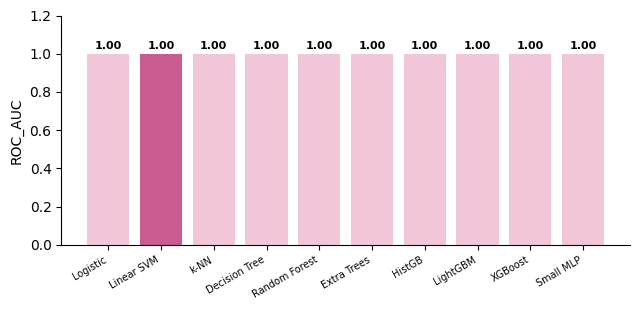

In [7]:
import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#C95B91' if i == highlight else '#F0C6D8' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30); plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

bar_chart(res.model, res.iloc[:, 1], res.columns[1], 'report/fig_rq2_models.png', highlight=int(res.iloc[:, 1].idxmax()), fmt='{:.2f}')

## Cổng khả thi: có nên xoay câu hỏi không

- **Làm gì:** so mô hình tốt nhất với mốc đơn giản và in ra một trong ba kết luận.
- **Vì sao:** nếu mô hình không hơn mốc hoặc bài toán quá dễ, nhóm xoay câu hỏi ngay ở đây thay vì cố chỉnh mô hình. Xoay câu hỏi nghĩa là đổi điều được hỏi cho khớp với điều dữ liệu trả lời được, không phải chọn lại số liệu cho đẹp.

**Các hướng xoay của đề tài này:**

1. Mọi mô hình đạt gần 100% là kết quả chính, không phải lỗi: giữ trục "vì sao dễ" và quy tắc một dòng.
2. Nếu muốn thêm một kết quả dương: báo mô hình nhỏ nhất đạt cùng điểm số với chi phí thấp hơn hàng nghìn lần.
3. Nếu phản biện đòi bài toán khó hơn: chỉ giữ các địa chỉ lừa đảo bắt đầu bằng https://www. và đo lại tỷ lệ bắt được.

**Quyết định của nhóm (giữ câu hỏi hay xoay theo hướng nào, vì sao):** ...

In [8]:
best = res.sort_values('ROC_AUC').iloc[-1]; spread = res.ROC_AUC.max() - res.ROC_AUC.min()
print('best model %s: ROC-AUC %.4f, PR-AUC %.4f | spread between models %.4f' % (best.model, best.ROC_AUC, best.PR_AUC, spread))
verdict = 'TOO EASY: every model is near the ceiling, so the comparison says little; explain why the task is easy or use a harder protocol (RQ3)' if best.ROC_AUC >= 0.995 else 'GOOD: there is a clear signal and room to compare models' if best.ROC_AUC >= 0.75 else 'WEAK: the signal is weak, pivot the target or the features (see the options above) and report this result honestly'
print(verdict); pd.Series({'best_model': best.model, 'ROC_AUC': best.ROC_AUC, 'PR_AUC': best.PR_AUC, 'spread': spread, 'verdict': verdict}).to_csv('report/table_feasibility_gate.csv')

best model XGBoost: ROC-AUC 1.0000, PR-AUC 1.0000 | spread between models 0.0004
TOO EASY: every model is near the ceiling, so the comparison says little; explain why the task is easy or use a harder protocol (RQ3)


## Bước 6b. Câu hỏi thứ ba (RQ3)

- **Làm gì:** Huấn luyện lại mười mô hình này trên sáu bộ đặc trưng và cả mười mô hình khi chỉ huấn luyện trên ba tên miền cấp cao phổ biến nhất.
- **Vì sao:** đây là đóng góp chính của bài; mỗi bảng `report/table_rq3_*.csv` ứng với một ý trong mục Results.
- **Kiểm tra:** đọc từng bảng in ra và viết một câu kết luận có số cho mỗi bảng. Nếu kết quả trái dự kiến trong đề cương thì báo đúng như vậy và tìm nguyên nhân, không chỉnh code cho ra kết quả mong muốn.

In [9]:
# Step 6b: RQ3, how much of the near-perfect score rests on one feature, what an address-only detector achieves, and what happens on top-level domains never seen
FPR = 0.01                                               # false-alarm budget: at most 1% of legitimate addresses may be blocked
def caught(m, cols, A, V, B):                            # share of phishing caught when the threshold is set on validation data at the budget
    m.fit(A[cols], A[TARGET]); t = np.quantile(proba(m, V.loc[V[TARGET] == 0, cols]), 1 - FPR); p = proba(m, B[cols])
    return roc_auc_score(B[TARGET], p), float((p[B[TARGET].to_numpy() == 1] >= t).mean()), float((p[B[TARGET].to_numpy() == 0] >= t).mean())
SETS = {'1 all features': X_cols, '2 without the similarity index': ADDRESS + PAGE, '3 address only, with the similarity index': SHORTCUT + ADDRESS,
        '4 address only, no similarity index': ADDRESS, '5 address only, no similarity index, no TLD statistics': [c for c in ADDRESS if c not in ('TLDLegitimateProb', 'URLCharProb')],
        '6 page only': PAGE}
rows = []
for tag, cols in SETS.items():                           # (1) feature ladder for all ten models
    for name, make in models.items():
        auc, det, fa = caught(make(0), cols, train, valid, test); rows.append([tag, name, len(cols), auc, det, fa])
lad = pd.DataFrame(rows, columns=['feature_set', 'model', 'n_features', 'ROC_AUC', 'caught_at_1pct_false_alarms', 'false_alarm_rate'])
lad.to_csv('report/table_rq3_feature_ladder.csv', index=False)
print(lad.groupby('feature_set').agg(n_features=('n_features', 'first'), ROC_AUC=('ROC_AUC', 'mean'), caught_mean=('caught_at_1pct_false_alarms', 'mean'), caught_best=('caught_at_1pct_false_alarms', 'max')).round(4))
one = feat[SHORTCUT[0]]; yy = feat[TARGET].to_numpy(); flag = 1 - feat.starts_https_www.to_numpy()      # one-line rule: phishing unless the address starts with https://www.
rule = pd.Series({'ROC_AUC_of_similarity_index_alone': roc_auc_score(yy, -one), 'legitimate_with_index_100_pct': float(100 * (one[yy == 0] >= 100).mean()),
        'rule_accuracy': float((flag == yy).mean()), 'rule_caught': float(flag[yy == 1].mean()), 'rule_false_alarm_rate': float(flag[yy == 0].mean()),
        'best_model_accuracy_all_features': float(max((proba(m, X_te) >= 0.5).astype(int).__eq__(y_te.to_numpy()).mean() for m in fitted.values()))})
rule.rename('value').to_csv('report/table_rq3_one_line_rule.csv'); print(rule.round(4))
# (2) top-level domains never seen in training: the rarer domains are held out as a group
FAM = list(models); big = pool.TLD.value_counts().index[:3]; rows = []
A = train[train.TLD.isin(big)]; V = valid[valid.TLD.isin(big)]; B_in = test[test.TLD.isin(big)]; B_out = test[~test.TLD.isin(big)]
for tag, cols in [('all features', X_cols), ('address only, no similarity index', ADDRESS)]:
    for name in FAM:
        a1, d1, f1 = caught(models[name](0), cols, A, V, B_in); m = models[name](0).fit(A[cols], A[TARGET])
        t = np.quantile(proba(m, V.loc[V[TARGET] == 0, cols]), 1 - FPR); p = proba(m, B_out[cols]); yb = B_out[TARGET].to_numpy()
        rows.append([tag, name, len(B_in), len(B_out), d1, float((p[yb == 1] >= t).mean()), f1, float((p[yb == 0] >= t).mean())])
tld = pd.DataFrame(rows, columns=['features', 'model', 'test_seen_tld', 'test_unseen_tld', 'caught_seen_tld', 'caught_unseen_tld', 'false_alarms_seen_tld', 'false_alarms_unseen_tld'])
tld.to_csv('report/table_rq3_unseen_tld.csv', index=False); print('training top-level domains:', list(big)); print(tld.round(3))

                                                    n_features  ROC_AUC  \
feature_set                                                               
1 all features                                              50   1.0000   
2 without the similarity index                              49   0.9998   
3 address only, with the similarity index                   22   0.9999   
4 address only, no similarity index                         21   0.9983   
5 address only, no similarity index, no TLD sta...          19   0.9980   
6 page only                                                 28   0.9991   

                                                    caught_mean  caught_best  
feature_set                                                                   
1 all features                                           0.9999       1.0000  
2 without the similarity index                           0.9997       1.0000  
3 address only, with the similarity index                0.9998       1.0000  
4 ad

### Bước 6b-2. Đối chứng cùng kích thước cho phép thử tên miền chưa thấy

- **Làm gì:** huấn luyện lại cả mười mô hình trên một mẫu ngẫu nhiên lấy từ mọi tên miền cấp cao, có cùng số dòng huấn luyện và validation với mẫu chỉ gồm .com, .org, .net; đánh giá trên đúng tập kiểm thử tên miền chưa thấy. Chạy cho bộ 21 đặc trưng địa chỉ và bộ 19 đặc trưng (bỏ `TLDLegitimateProb`, `URLCharProb`).
- **Vì sao:** phép thử tên miền chưa thấy đổi cả mức đa dạng tên miền lẫn số dòng huấn luyện; đối chứng này tách hai yếu tố.
- **Kiểm tra:** `report/table_rq3_size_matched_control.csv` tồn tại; cột `FA_holdout_seed0` khớp cột báo động giả của tên miền chưa thấy ở `table_rq3_unseen_tld.csv`.

In [10]:
# Step 6b-2: size-matched random control for the unseen-TLD test (same training size, same validation size, same test set; TLDs are not restricted)
FAM = list(models)
ADDR19 = [c for c in ADDRESS if c not in ('TLDLegitimateProb', 'URLCharProb')]
def caught_fa(m, cols, Vd, Bd):                          # catch rate and false-alarm rate at the 1% validation threshold
    t = np.quantile(proba(m, Vd.loc[Vd[TARGET] == 0, cols]), 1 - FPR); p = proba(m, Bd[cols]); y = Bd[TARGET].to_numpy()
    return float((p[y == 1] >= t).mean()), float((p[y == 0] >= t).mean())
rows = []
for tag, cols in [('address only, no similarity index', ADDRESS), ('address only, no similarity index, no TLD statistics', ADDR19)]:
    for name in FAM:
        hold = np.array([caught_fa(models[name](s).fit(A[cols], A[TARGET]), cols, V, B_out) for s in range(5)])      # seed 0 is the row in the unseen-TLD table
        ctrl = []
        for d in range(5):                               # five random draws of the same size as A and V, taken from all TLDs
            Ar, Vr = train.sample(len(A), random_state=d), valid.sample(len(V), random_state=d)
            ctrl.append(caught_fa(models[name](d).fit(Ar[cols], Ar[TARGET]), cols, Vr, B_out))
        ctrl = np.array(ctrl)
        rows.append([tag, name, len(A), len(B_out), int((B_out[TARGET] == 0).sum()), hold[0, 0], hold[0, 1], hold[:, 1].mean(), hold[:, 1].std(), ctrl[:, 0].mean(), ctrl[:, 1].mean(), ctrl[:, 1].std()])
ctl = pd.DataFrame(rows, columns=['features', 'model', 'n_train', 'n_test_unseen', 'n_legit_unseen', 'caught_holdout_seed0', 'FA_holdout_seed0',
                                  'FA_holdout_mean5', 'FA_holdout_sd5', 'caught_control_mean5', 'FA_control_mean5', 'FA_control_sd5'])
ctl.to_csv('report/table_rq3_size_matched_control.csv', index=False); print(ctl.round(4).to_string())

                                                features          model  n_train  n_test_unseen  n_legit_unseen  caught_holdout_seed0  FA_holdout_seed0  FA_holdout_mean5  FA_holdout_sd5  caught_control_mean5  FA_control_mean5  FA_control_sd5
0                      address only, no similarity index       Logistic    35202           8286            3805                0.9958            0.0715            0.0715          0.0000                0.9959            0.0152          0.0008
1                      address only, no similarity index     Linear SVM    35202           8286            3805                0.9969            0.3246            0.3246          0.0000                0.9969            0.0143          0.0015
2                      address only, no similarity index           k-NN    35202           8286            3805                0.9949            0.1714            0.1714          0.0000                0.9942            0.0128          0.0010
3                      address o

### Bước 6b-3. Chẩn đoán ngưỡng cho phép thử tên miền chưa thấy

- **Làm gì:** với 21 đặc trưng địa chỉ và seed 0, đếm số giá trị điểm khác nhau của URL hợp pháp trong validation, tỷ lệ báo động giả thực tế tại ngưỡng phân vị 99 trên validation, và (riêng Linear SVM) các phân vị của điểm quyết định ở validation so với tên miền chưa thấy.
- **Vì sao:** k-NN và Decision Tree cho rất ít giá trị điểm khác nhau nên ngưỡng phân vị 99 có thể rơi vào một điểm trùng và cho báo động giả trên validation cao hơn 1%; Linear SVM có báo động giả cao nhất ở tên miền chưa thấy và cần một chẩn đoán.
- **Kiểm tra:** `report/table_rq3_threshold_diagnostic.csv` và `report/table_rq3_svm_score_quantiles.csv` tồn tại; cột `unseen_FA_at_threshold` khớp cột báo động giả của tên miền chưa thấy ở `table_rq3_unseen_tld.csv` cho bộ đặc trưng địa chỉ.

In [11]:
# Step 6b-3: threshold diagnostic for the unseen-TLD test (21 address features, seed 0)
rows = []
for name in models:
    m = models[name](0).fit(A[ADDRESS], A[TARGET]); pv = proba(m, V.loc[V[TARGET] == 0, ADDRESS]); po = proba(m, B_out.loc[B_out[TARGET] == 0, ADDRESS]); thr = float(np.quantile(pv, 1 - FPR))
    rows.append([name, len(np.unique(pv)), float((pv >= thr).mean()), float((po >= thr).mean())])
dg = pd.DataFrame(rows, columns=['model', 'distinct_valid_legit_scores', 'valid_FA_at_threshold', 'unseen_FA_at_threshold'])
dg.to_csv('report/table_rq3_threshold_diagnostic.csv', index=False); print(dg.round(4).to_string())
svm_m = models['Linear SVM'](0).fit(A[ADDRESS], A[TARGET])      # decision-function scores of legitimate addresses: validation (seen TLDs) against test (unseen TLDs)
dv = svm_m.decision_function(V.loc[V[TARGET] == 0, ADDRESS]); do = svm_m.decision_function(B_out.loc[B_out[TARGET] == 0, ADDRESS]); thr_svm = float(np.quantile(dv, 1 - FPR))
sq = pd.DataFrame({'quantile': [0.50, 0.90, 0.99], 'valid_legit_decision': np.quantile(dv, [0.50, 0.90, 0.99]), 'unseen_legit_decision': np.quantile(do, [0.50, 0.90, 0.99])})
sq.to_csv('report/table_rq3_svm_score_quantiles.csv', index=False); print(sq.round(3).to_string(index=False)); print('threshold on the decision scale: %.3f; unseen legitimate above it: %.4f' % (thr_svm, float((do >= thr_svm).mean())))


           model  distinct_valid_legit_scores  valid_FA_at_threshold  unseen_FA_at_threshold
0       Logistic                         7584                 0.0100                  0.0715
1     Linear SVM                         7584                 0.0100                  0.3246
2           k-NN                           11                 0.0466                  0.1714
3  Decision Tree                           23                 0.0204                  0.1921
4  Random Forest                         2487                 0.0100                  0.1611
5    Extra Trees                         4066                 0.0100                  0.0933
6         HistGB                         1760                 0.0100                  0.0741
7       LightGBM                         3533                 0.0100                  0.0544
8        XGBoost                         3275                 0.0100                  0.1658
9      Small MLP                         7584                 0.0100  

## Bước 6c. Kiểm tra bổ sung và bảng tham số

- **Làm gì:** chạy phép kiểm tra bổ sung của đề tài và lưu tham số mô hình. Thời gian suy luận mỗi địa chỉ là trung vị của 15 lần chạy theo lô trên tập test, sau năm lần khởi động; phần chọn cột được làm trước khi bấm giờ, và cấu hình máy ghi vào `report/table_timing_environment.csv`.
- **Vì sao:** bảng này đi vào phần thảo luận và phụ lục của bài.
- **Kiểm tra:** `report/params_best.json` và `report/table_timing_environment.csv` tồn tại.

In [12]:
# Step 6c: cost of each detector per address, the most useful address features, and parameters
import pickle, gc, os, sys, platform, subprocess, importlib.metadata as md
Xa = test[ADDRESS]                                       # columns selected once, before the clock starts: the timed calls measure the model, not pandas
rows = []
for name in models:                                      # address-only detector: stored size and time per address on this machine
    m = models[name](0).fit(train[ADDRESS], y_tr); [proba(m, Xa) for _ in range(5)]      # five warm-up calls, not timed
    reps = []
    for _ in range(15):                              # median of 15 timed calls, so a noisy call does not move the result
        gc.collect(); gc.disable(); t0 = time.perf_counter(); proba(m, Xa); dt = time.perf_counter() - t0; gc.enable(); reps.append(1e6 * dt / len(Xa))
    us = float(np.median(reps)); iqr = float(np.percentile(reps, 75) - np.percentile(reps, 25))
    r = lad[(lad.feature_set == '4 address only, no similarity index') & (lad.model == name)].iloc[0]
    rows.append([name, len(pickle.dumps(m)) / 1024, us, r.caught_at_1pct_false_alarms, iqr])
edge = pd.DataFrame(rows, columns=['model', 'size_kB', 'microseconds_per_address', 'caught_at_1pct_false_alarms', 'iqr_microseconds']); edge.to_csv('report/table_rq3_cost.csv', index=False); print(edge.round(3))
def cpu_name():                                          # the machine the times belong to
    try:
        if sys.platform.startswith('win'):
            import winreg; return winreg.QueryValueEx(winreg.OpenKey(winreg.HKEY_LOCAL_MACHINE, r'HARDWARE\DESCRIPTION\System\CentralProcessor\0'), 'ProcessorNameString')[0].strip()
        if sys.platform == 'darwin': return subprocess.check_output(['sysctl', '-n', 'machdep.cpu.brand_string'], text=True).strip()
        return [l.split(':', 1)[1].strip() for l in open('/proc/cpuinfo') if l.startswith('model name')][0]
    except Exception: return platform.processor() or platform.machine()
env = {'cpu': cpu_name(), 'logical_cores': os.cpu_count(), 'os': platform.platform(), 'python': platform.python_version()}
for p_ in ['numpy', 'pandas', 'scikit-learn', 'lightgbm', 'xgboost']: env[p_] = md.version(p_)
try: import psutil; env['ram_gb'] = round(psutil.virtual_memory().total / 2**30, 1)
except Exception: pass
pd.Series(env, name='value').rename_axis('item').to_csv('report/table_timing_environment.csv'); print(env)
assert os.path.exists('report/table_rq3_cost.csv') and os.path.exists('report/table_timing_environment.csv')
from sklearn.inspection import permutation_importance
best = edge.sort_values('caught_at_1pct_false_alarms').model.iloc[-1]; m = models[best](0).fit(train[ADDRESS], y_tr); s = test.sample(min(5000, len(test)), random_state=0)
imp = permutation_importance(m, s[ADDRESS], s[TARGET], scoring='roc_auc', n_repeats=3, random_state=0)
top = pd.DataFrame({'feature': ADDRESS, 'drop_in_ROC_AUC': imp.importances_mean}).sort_values('drop_in_ROC_AUC', ascending=False).head(8); top.to_csv('report/table_rq3_address_features.csv', index=False); print(best); print(top.round(4))
import json
json.dump({'best_address_only_model': best, 'false_alarm_budget': FPR, 'params': {k: str(v) for k, v in models[best](0).get_params().items()}}, open('report/params_best.json', 'w'), indent=2)

           model    size_kB  microseconds_per_address  \
0       Logistic      2.178                     0.461   
1     Linear SVM      2.066                     0.226   
2           k-NN  10314.504                   161.686   
3  Decision Tree     22.084                     0.171   
4  Random Forest  18284.763                    11.363   
5    Extra Trees  19039.160                    11.316   
6         HistGB    498.635                     5.374   
7       LightGBM   1023.987                    12.446   
8        XGBoost    711.439                     2.665   
9      Small MLP     91.499                     1.221   

   caught_at_1pct_false_alarms  iqr_microseconds  
0                        0.996             0.334  
1                        0.997             0.232  
2                        0.995             4.623  
3                        0.994             0.024  
4                        0.996             0.334  
5                        0.995             0.211  
6              

## Bước 6d. Kiểm tra bổ sung theo góp ý phản biện

Năm phép kiểm tra trả lời các góp ý: (1) chia theo tên miền, (2) luật một dòng trên đúng các tập mà mô hình được đánh giá, kèm khoảng tin cậy 95%, (3) kiểm định McNemar cho chênh lệch tỷ lệ bắt của Linear SVM, (4) đối chứng cùng kích thước sau khi bỏ các tên miền có trong tập held-out, (5) kiểm tra trên một bộ dữ liệu khác. Mỗi phép thử ghi một bảng `report/table_review_*.csv`; mọi số mới trong bài lấy từ các bảng này.

### 6d-1. Chia theo hostname (trường Domain)

- **Làm gì:** chia lại cùng pool 100.000 URL theo tỷ lệ 60/20/20 sao cho mỗi giá trị của trường Domain (hostname, ví dụ www.example.com) chỉ nằm trong một phần, rồi chạy mười mô hình với 50 đặc trưng và với 21 đặc trưng địa chỉ.
- **Vì sao:** nếu điểm gần tuyệt đối đến từ URL cùng tên miền nằm ở cả hai phía, điểm sẽ giảm khi chia theo hostname.
- **Kiểm tra:** không có giá trị Domain chung giữa các phần; `report/table_review_grouped_split.csv` tồn tại.

In [13]:
# Step 6d-1: hostname-grouped 60/20/20 split of the same pool (no Domain value, i.e. hostname, in two partitions)
from sklearn.model_selection import GroupShuffleSplit
print('random split: share of test URLs whose domain also occurs in training = %.4f' % test.Domain.isin(set(train.Domain)).mean())
i_tr, i_rest = next(GroupShuffleSplit(n_splits=1, test_size=0.4, random_state=0).split(pool, groups=pool.Domain)); g_tr, g_rest = pool.iloc[i_tr], pool.iloc[i_rest]
i_va, i_te = next(GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=0).split(g_rest, groups=g_rest.Domain)); g_va, g_te = g_rest.iloc[i_va], g_rest.iloc[i_te]
assert not (set(g_tr.Domain) & set(g_te.Domain)) and not (set(g_tr.Domain) & set(g_va.Domain)) and not (set(g_va.Domain) & set(g_te.Domain))
print('grouped split sizes', len(g_tr), len(g_va), len(g_te), '| phishing share', [round(float(x[TARGET].mean()), 4) for x in (g_tr, g_va, g_te)])
rv = []
for tag, cols in [('all features', X_cols), ('address only, no similarity index', ADDRESS)]:
    for name in models:
        auc, det, fa = caught(models[name](0), cols, g_tr, g_va, g_te); rv.append([tag, name, auc, det, fa])
grouped = pd.DataFrame(rv, columns=['features', 'model', 'ROC_AUC', 'caught_at_1pct_false_alarms', 'false_alarm_rate'])
grouped.to_csv('report/table_review_grouped_split.csv', index=False); print(grouped.round(6).to_string(index=False))

random split: share of test URLs whose domain also occurs in training = 0.0559
grouped split sizes 59860 20124 20016 | phishing share [0.4255, 0.434, 0.4342]
                         features         model  ROC_AUC  caught_at_1pct_false_alarms  false_alarm_rate
                     all features      Logistic 1.000000                     1.000000          0.010243
                     all features    Linear SVM 1.000000                     1.000000          0.009536
                     all features          k-NN 0.999701                     0.999540          0.015364
                     all features Decision Tree 1.000000                     1.000000          1.000000
                     all features Random Forest 1.000000                     1.000000          0.011038
                     all features   Extra Trees 1.000000                     1.000000          0.008565
                     all features        HistGB 1.000000                     1.000000          0.011391
          

### 6d-2. Luật một dòng trên cùng các tập đánh giá, kèm khoảng tin cậy 95%

- **Làm gì:** chạy luật "phishing nếu URL không bắt đầu bằng `https://www.`" trên tập test ngẫu nhiên, tập test chia theo hostname, tập TLD đã thấy và tập TLD held-out; tính khoảng Wilson 95% cho tỷ lệ bắt và tỷ lệ báo nhầm, và cho tỷ lệ báo nhầm held-out của mười mô hình.
- **Vì sao:** trước đây luật được chấm trên toàn bộ dữ liệu còn mô hình trên tập test, nên phép so sánh chưa ghép cặp.
- **Kiểm tra:** `report/table_review_rule_sets.csv` và `report/table_review_heldout_ci.csv` tồn tại.

In [14]:
# Step 6d-2: the one-line rule on the same evaluation sets as the models; 95% Wilson intervals
from scipy.stats import binomtest
def wilson(k, n, z=1.959964):
    p = k / n; d_ = 1 + z * z / n; c_ = (p + z * z / (2 * n)) / d_; h_ = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d_
    return max(c_ - h_, 0.0), c_ + h_
def rule_row(D, name):
    f = D.starts_https_www.to_numpy() == 0; y = D[TARGET].to_numpy() == 1
    kc, nc, kf, nf = int(f[y].sum()), int(y.sum()), int(f[~y].sum()), int((~y).sum())
    return [name, len(D), nc, nf, float((f == y).mean()), kc / nc, *wilson(kc, nc), kf / nf, *wilson(kf, nf)]
RULE_COLS = ['evaluation_set', 'urls', 'phishing', 'legitimate', 'accuracy', 'caught', 'caught_lo95', 'caught_hi95', 'false_alarms', 'false_alarms_lo95', 'false_alarms_hi95']
rule_sets = pd.DataFrame([rule_row(feat, 'all cleaned URLs'), rule_row(test, 'random-split test'), rule_row(g_te, 'hostname-grouped test'),
                          rule_row(B_in, 'seen-TLD test'), rule_row(B_out, 'held-out-TLD test')], columns=RULE_COLS)
rule_sets.to_csv('report/table_review_rule_sets.csv', index=False); print(rule_sets.round(5).to_string(index=False))
n_lg = int((B_out[TARGET] == 0).sum())
hci = tld[tld.features == 'address only, no similarity index'][['model', 'false_alarms_unseen_tld']].copy()
hci['lo95'], hci['hi95'] = zip(*[wilson(round(v * n_lg), n_lg) for v in hci.false_alarms_unseen_tld])
hci.to_csv('report/table_review_heldout_ci.csv', index=False); print('held-out legitimate URLs:', n_lg); print(hci.round(4).to_string(index=False))

       evaluation_set   urls  phishing  legitimate  accuracy  caught  caught_lo95  caught_hi95  false_alarms  false_alarms_lo95  false_alarms_hi95
     all cleaned URLs 235370    100520      134850   0.98961 0.97568      0.97471      0.97661           0.0                0.0            0.00003
    random-split test  20000      8579       11421   0.98950 0.97552      0.97203      0.97858           0.0                0.0            0.00034
hostname-grouped test  20016      8691       11325   0.99036 0.97779      0.97448      0.98069           0.0                0.0            0.00034
        seen-TLD test  11714      4098        7616   0.99018 0.97194      0.96642      0.97657           0.0                0.0            0.00050
    held-out-TLD test   8286      4481        3805   0.98853 0.97880      0.97415      0.98263           0.0                0.0            0.00101
held-out legitimate URLs: 3805
        model  false_alarms_unseen_tld   lo95   hi95
     Logistic                   0.

### 6d-3. Linear SVM có thật sự bắt nhiều hơn không

- **Làm gì:** với 21 đặc trưng địa chỉ (seed 0), so từng URL phishing của tập test giữa Linear SVM và từng mô hình khác bằng kiểm định McNemar chính xác.
- **Vì sao:** chênh lệch tỷ lệ bắt giữa các mô hình chỉ 0,1 đến 0,3 điểm phần trăm, tức vài URL.
- **Kiểm tra:** `report/table_review_mcnemar.csv` tồn tại.

In [15]:
# Step 6d-3: exact McNemar test of the Linear SVM against each other model (address features, seed 0, same test URLs)
yt = test[TARGET].to_numpy() == 1; flags = {}
for name in models:
    mm = models[name](0).fit(train[ADDRESS], y_tr); tt = np.quantile(proba(mm, valid.loc[valid[TARGET] == 0, ADDRESS]), 1 - FPR)
    flags[name] = proba(mm, test[ADDRESS]) >= tt
rv = []
for name in models:
    if name == 'Linear SVM': continue
    a_, b_ = flags['Linear SVM'][yt], flags[name][yt]; n01, n10 = int((a_ & ~b_).sum()), int((~a_ & b_).sum())
    rv.append([name, 100 * b_.mean(), n01, n10, n01 - n10, binomtest(n01, n01 + n10, 0.5).pvalue if n01 + n10 else 1.0])
mcn = pd.DataFrame(rv, columns=['model', 'caught_pct', 'svm_only', 'other_only', 'net_urls_for_svm', 'p_exact_mcnemar'])
print('Linear SVM caught %.2f%% of %d test phishing URLs' % (100 * flags['Linear SVM'][yt].mean(), yt.sum()))
mcn.to_csv('report/table_review_mcnemar.csv', index=False); print(mcn.round(4).to_string(index=False))

Linear SVM caught 99.69% of 8579 test phishing URLs
        model  caught_pct  svm_only  other_only  net_urls_for_svm  p_exact_mcnemar
     Logistic     99.5571        11           0                11           0.0010
         k-NN     99.5337        15           2                13           0.0023
Decision Tree     99.4405        22           1                21           0.0000
Random Forest     99.5804        12           3                 9           0.0352
  Extra Trees     99.5104        15           0                15           0.0001
       HistGB     99.6037         9           2                 7           0.0654
     LightGBM     99.6270         7           2                 5           0.1797
      XGBoost     99.5920        10           2                 8           0.0386
    Small MLP     99.5454        12           0                12           0.0005


### 6d-4. Đối chứng cùng kích thước không chung tên miền với tập held-out

- **Làm gì:** lặp lại đối chứng của bước 6b-2 (21 đặc trưng địa chỉ, năm lần lấy mẫu) sau khi bỏ khỏi tập huấn luyện và validation mọi URL có tên miền nằm trong tập test held-out.
- **Vì sao:** đối chứng ngẫu nhiên có thể chứa đúng các tên miền của tập held-out, làm tỷ lệ báo nhầm của đối chứng thấp giả tạo.
- **Kiểm tra:** đối chứng không chung dòng nào với tập held-out; `report/table_review_control_domain_disjoint.csv` tồn tại.

In [16]:
# Step 6d-4: size-matched control without the domains of the held-out test set
held_dom = set(B_out.Domain); tr_nd, va_nd = train[~train.Domain.isin(held_dom)], valid[~valid.Domain.isin(held_dom)]
print('training rows removed:', len(train) - len(tr_nd), '| validation rows removed:', len(valid) - len(va_nd),
      '| control rows shared with the held-out test set:', len((set(train.row_id) | set(valid.row_id)) & set(B_out.row_id)))
rv = []
for name in models:
    r_ = []
    for d in range(5):
        Ar, Vr = tr_nd.sample(len(A), random_state=d), va_nd.sample(len(V), random_state=d)
        r_.append(caught_fa(models[name](d).fit(Ar[ADDRESS], Ar[TARGET]), ADDRESS, Vr, B_out))
    r_ = np.array(r_); rv.append([name, r_[:, 0].mean(), r_[:, 1].mean(), r_[:, 1].std()])
ctl_dd = pd.DataFrame(rv, columns=['model', 'caught_mean5', 'FA_mean5', 'FA_sd5'])
ctl_dd.to_csv('report/table_review_control_domain_disjoint.csv', index=False); print(ctl_dd.round(4).to_string(index=False))

training rows removed: 1578 | validation rows removed: 509 | control rows shared with the held-out test set: 0
        model  caught_mean5  FA_mean5  FA_sd5
     Logistic        0.9958    0.0143  0.0011
   Linear SVM        0.9969    0.0124  0.0012
         k-NN        0.9944    0.0216  0.0184
Decision Tree        0.9932    0.0220  0.0048
Random Forest        0.9958    0.0147  0.0010
  Extra Trees        0.9951    0.0115  0.0009
       HistGB        0.9962    0.0127  0.0025
     LightGBM        0.9960    0.0102  0.0009
      XGBoost        0.9963    0.0143  0.0020
    Small MLP        0.9958    0.0155  0.0036


### 6d-5. Kiểm tra trên bộ dữ liệu khác (ISCX-URL-2016 và PhishTank)

- **Làm gì:** tính lại các đặc trưng địa chỉ từ chuỗi URL bằng cùng một hàm cho cả hai bộ dữ liệu; huấn luyện và đặt ngưỡng trên PhiUSIIL, rồi chấm trên 35.378 URL hợp lệ của ISCX-URL-2016 và 14.855 URL PhishTank đã xác minh. Đối chiếu bằng cách huấn luyện ngay trên bộ dữ liệu đó (chia 60/20/20).
- **Vì sao:** để xem điểm gần tuyệt đối trên PhiUSIIL có còn giữ trên dữ liệu có URL hợp lệ là trang thật hay không.
- **Dữ liệu:** `data/external/1.Benign_list_big_final.csv` và `data/external/2.online-valid.csv`, lấy từ github.com/shreyagopal/Phishing-Website-Detection-by-Machine-Learning-Techniques (thư mục DataFiles).
- **Kiểm tra:** `report/table_review_cross_dataset.csv` và `report/table_review_cross_info.csv` tồn tại.

In [17]:
# Step 6d-5: cross-dataset test; address features recomputed from the URL string with one code path for both datasets
import re, ipaddress
from urllib.parse import urlsplit
def url_feats(u):
    u = str(u).strip()
    try: host = urlsplit(u).hostname or ''
    except Exception: host = ''
    try: ipaddress.ip_address(host); ip = 1
    except Exception: ip = 0
    tld_ = host.rsplit('.', 1)[-1] if '.' in host else ''; L = max(len(u), 1)
    obf = len(re.findall(r'%[0-9a-fA-F]{2}', u)); let = sum(c.isascii() and c.isalpha() for c in u); dig = sum(c.isdigit() for c in u)
    eq, qm, amp = u.count('='), u.count('?'), u.count('&'); other = sum((not c.isalnum()) and c not in '=?&' for c in u)
    return dict(URLLength=len(u), DomainLength=len(host), IsDomainIP=ip, TLDLength=len(tld_), NoOfSubDomain=max(host.count('.') - 1, 0),
                HasObfuscation=int(obf > 0), NoOfObfuscatedChar=obf, ObfuscationRatio=obf / L, NoOfLettersInURL=let, LetterRatioInURL=let / L,
                NoOfDegitsInURL=dig, DegitRatioInURL=dig / L, NoOfEqualsInURL=eq, NoOfQMarkInURL=qm, NoOfAmpersandInURL=amp,
                NoOfOtherSpecialCharsInURL=other, SpacialCharRatioInURL=(other + eq + qm + amp) / L, IsHTTPS=int(u.lower().startswith('https://')))
frame = lambda urls: pd.DataFrame([url_feats(u) for u in urls])
url_of = con.execute('SELECT row_id, URL FROM ph').df().set_index('row_id').URL
ben = pd.read_csv('data/external/1.Benign_list_big_final.csv', header=None, names=['url']).url.dropna().astype(str).drop_duplicates()
pht = pd.read_csv('data/external/2.online-valid.csv').url.dropna().astype(str).drop_duplicates()
ext = pd.DataFrame({'url': list(ben) + list(pht), 'phishing': [0] * len(ben) + [1] * len(pht)}).drop_duplicates('url')
Xtr_u, Xva_u, Xte_u, Xex = frame(url_of.loc[train.row_id]), frame(url_of.loc[valid.row_id]), frame(url_of.loc[test.row_id]), frame(ext.url)
ytr_u, yva_u, yte_u, yex = train[TARGET].to_numpy(), valid[TARGET].to_numpy(), test[TARGET].to_numpy(), ext.phishing.to_numpy()
agree = {c: float((Xte_u[c].to_numpy() == test[c].to_numpy()).mean()) for c in Xte_u.columns if 'Ratio' not in c}
e_tr, e_rest = train_test_split(ext, test_size=0.4, random_state=0, stratify=ext.phishing); e_va, e_te = train_test_split(e_rest, test_size=0.5, random_state=0, stratify=e_rest.phishing)
Etr, Eva, Ete = frame(e_tr.url), frame(e_va.url), frame(e_te.url)
def at_t(p, y, t): f = p >= t; return float(f[y == 1].mean()), float(f[y == 0].mean())
rv = []
for name in models:
    mm = models[name](0).fit(Xtr_u, ytr_u); tt = np.quantile(proba(mm, Xva_u[yva_u == 0]), 1 - FPR)
    p_te, p_ex = proba(mm, Xte_u), proba(mm, Xex); c1, f1 = at_t(p_te, yte_u, tt); c2, f2 = at_t(p_ex, yex, tt)
    m2 = models[name](0).fit(Etr, e_tr.phishing.to_numpy()); t2 = np.quantile(proba(m2, Eva[e_va.phishing.to_numpy() == 0]), 1 - FPR); p2 = proba(m2, Ete)
    c3, f3 = at_t(p2, e_te.phishing.to_numpy(), t2)
    rv.append([name, roc_auc_score(yte_u, p_te), c1, f1, roc_auc_score(yex, p_ex), c2, f2, roc_auc_score(e_te.phishing, p2), c3, f3])
cross = pd.DataFrame(rv, columns=['model', 'auc_phiusiil_test', 'caught_phiusiil_test', 'fa_phiusiil_test', 'auc_external', 'caught_external', 'fa_external',
                                  'auc_within_external', 'caught_within_external', 'fa_within_external'])
cross.to_csv('report/table_review_cross_dataset.csv', index=False); print(cross.round(4).to_string(index=False))
r_ext = ~ext.url.str.startswith('https://www.').to_numpy()
info = pd.Series({'external_urls': len(ext), 'external_benign': int((yex == 0).sum()), 'external_phishing': int((yex == 1).sum()),
                  'benign_starting_https_www_pct': 100 * float((~r_ext[yex == 0]).mean()), 'rule_caught_external_pct': 100 * float(r_ext[yex == 1].mean()),
                  'rule_false_alarms_external_pct': 100 * float(r_ext[yex == 0].mean()),
                  'integer_features_matching_dataset_ge_98_6pct': int(sum(v >= 0.986 for v in agree.values())), 'integer_features_compared': len(agree),
                  **{'agree_' + k: v for k, v in agree.items()}})
info.rename('value').to_csv('report/table_review_cross_info.csv'); print(info.round(4).to_string())
for f in ['grouped_split', 'rule_sets', 'heldout_ci', 'mcnemar', 'control_domain_disjoint', 'cross_dataset', 'cross_info']:
    assert os.path.exists('report/table_review_%s.csv' % f), f
print('Step 6d: all review tables written')

        model  auc_phiusiil_test  caught_phiusiil_test  fa_phiusiil_test  auc_external  caught_external  fa_external  auc_within_external  caught_within_external  fa_within_external
     Logistic             0.9954                0.9817            0.0119        0.3404           0.9861          1.0               0.9749                  0.8320              0.0068
   Linear SVM             0.9959                0.9860            0.0114        0.2801           0.9910          1.0               0.9728                  0.8118              0.0072
         k-NN             0.9960                0.9871            0.0101        0.4839           0.9894          1.0               0.9951                  0.9650              0.0136
Decision Tree             0.9956                0.9797            0.0098        0.4870           0.9879          1.0               0.9875                  0.9667              0.0064
Random Forest             0.9973                0.9907            0.0086        0.2250    

### 6d-6. Cách lưu giao thức ở bộ dữ liệu ngoài và phép thử sau khi chuẩn hoá

- **Làm gì:** (a) đếm tỷ lệ URL bắt đầu bằng `http://`, `https://`, không có giao thức, và có `www.` ngay sau giao thức ở bốn nhóm: URL hợp lệ và URL lừa đảo của PhiUSIIL, URL hợp lệ của ISCX-URL-2016, URL PhishTank; (b) với các đặc trưng nguyên mà hàm `url_feats` không tái tạo đúng (khớp dưới 98,6%), in độ lệch giữa giá trị trong dataset và giá trị tính lại; (c) bỏ giao thức và `www.` ở đầu mọi URL, gắn cùng một tiền tố `http://` cho tất cả, bỏ `IsHTTPS`, rồi chạy lại đúng phép thử 6d-5.
- **Vì sao:** phản biện hỏi kết quả "mô hình chặn 100% URL hợp lệ của ISCX" có phải chỉ do hai bộ dữ liệu lưu giao thức khác nhau hay không, và ba đặc trưng không khớp lệch bao nhiêu.
- **Kiểm tra:** `report/table_review_cross_scheme.csv`, `report/table_review_cross_feature_offsets.csv` và `report/table_review_cross_normalised.csv` tồn tại.

In [18]:
# Step 6d-6: (a) how each source stores the scheme; (b) integer features the recomputation does not reproduce;
# (c) the cross-dataset test again after removing the scheme and a leading "www." from every URL (IsHTTPS dropped)
lab_of = con.execute('SELECT row_id, phishing FROM ph').df().set_index('row_id').phishing.loc[url_of.index]
def form(s):                                             # how the URLs of one group are stored, in percent
    s = pd.Series(list(s)).astype(str).str.strip().str.lower()
    return {'urls': len(s), 'http_pct': 100 * s.str.startswith('http://').mean(), 'https_pct': 100 * s.str.startswith('https://').mean(),
            'no_scheme_pct': 100 * (~s.str.match(r'[a-z][a-z0-9+.\-]*://')).mean(), 'www_after_scheme_pct': 100 * s.str.match(r'https?://www\.').mean()}
scheme = pd.DataFrame({'PhiUSIIL legitimate': form(url_of[lab_of == 0]), 'PhiUSIIL phishing': form(url_of[lab_of == 1]),
                       'ISCX-URL-2016 benign': form(ext.url[ext.phishing == 0]), 'PhishTank': form(ext.url[ext.phishing == 1])}).T
scheme.to_csv('report/table_review_cross_scheme.csv'); print(scheme.round(2).to_string(), '\n')
off = []
for c, v in agree.items():                               # (b) dataset value minus recomputed value on the PhiUSIIL test URLs
    if v >= 0.986: continue
    dlt = test[c].to_numpy().astype(float) - Xte_u[c].to_numpy().astype(float); vals, cnt = np.unique(dlt, return_counts=True)
    off.append([c, 100 * v, float(np.median(dlt)), float(vals[cnt.argmax()]), 100 * cnt.max() / len(dlt)])
off = pd.DataFrame(off, columns=['feature', 'agree_pct', 'median_dataset_minus_recomputed', 'most_common_difference', 'most_common_difference_pct'])
off.to_csv('report/table_review_cross_feature_offsets.csv', index=False); print(off.round(2).to_string(index=False), '\n')
bare = lambda urls: 'http://' + pd.Series(list(urls)).astype(str).str.strip().str.replace(r'^[A-Za-z][A-Za-z0-9+.\-]*://', '', regex=True).str.replace(r'(?i)^www\.', '', regex=True)
frame_n = lambda urls: frame(bare(urls)).drop(columns='IsHTTPS')     # (c) one prefix for every URL, so the scheme carries no information
Ntr, Nva, Nte, Nex = frame_n(url_of.loc[train.row_id]), frame_n(url_of.loc[valid.row_id]), frame_n(url_of.loc[test.row_id]), frame_n(ext.url)
NEtr, NEva, NEte = frame_n(e_tr.url), frame_n(e_va.url), frame_n(e_te.url)
rv = []
for name in models:
    mm = models[name](0).fit(Ntr, ytr_u); tt = np.quantile(proba(mm, Nva[yva_u == 0]), 1 - FPR)
    p_te, p_ex = proba(mm, Nte), proba(mm, Nex); c1, f1 = at_t(p_te, yte_u, tt); c2, f2 = at_t(p_ex, yex, tt)
    m2 = models[name](0).fit(NEtr, e_tr.phishing.to_numpy()); t2 = np.quantile(proba(m2, NEva[e_va.phishing.to_numpy() == 0]), 1 - FPR); p2 = proba(m2, NEte)
    c3, f3 = at_t(p2, e_te.phishing.to_numpy(), t2)
    rv.append([name, roc_auc_score(yte_u, p_te), c1, f1, roc_auc_score(yex, p_ex), c2, f2, roc_auc_score(e_te.phishing, p2), c3, f3])
cross_n = pd.DataFrame(rv, columns=cross.columns)
cross_n.to_csv('report/table_review_cross_normalised.csv', index=False); print('features after normalisation:', Ntr.shape[1]); print(cross_n.round(4).to_string(index=False))
for f in ['cross_scheme', 'cross_feature_offsets', 'cross_normalised']: assert os.path.exists('report/table_review_%s.csv' % f), f
print('Step 6d-6: tables written')

                          urls  http_pct  https_pct  no_scheme_pct  www_after_scheme_pct
PhiUSIIL legitimate   134850.0      0.00     100.00            0.0                100.00
PhiUSIIL phishing     100520.0     51.37      48.63            0.0                 41.50
ISCX-URL-2016 benign   35378.0     94.49       5.51            0.0                  0.39
PhishTank              14855.0     54.35      45.65            0.0                 14.30 

                   feature  agree_pct  median_dataset_minus_recomputed  most_common_difference  most_common_difference_pct
                 URLLength      20.39                             -1.0                    -1.0                       79.61
          NoOfLettersInURL       0.00                             -9.0                    -9.0                       57.58
NoOfOtherSpecialCharsInURL       0.08                             -4.0                    -4.0                       80.18 

features after normalisation: 17
        model  auc_phiusii

In [19]:
# Step 6d-6 (feature count): address features recomputed from the URL string, before and after the prefix is normalised
print('address features recomputed from the URL string:', Xtr_u.shape[1], '| after normalisation (IsHTTPS dropped):', Ntr.shape[1])

address features recomputed from the URL string: 18 | after normalisation (IsHTTPS dropped): 17


### 6d-7. Vì sao ROC-AUC trên bộ dữ liệu ngoài thấp hơn 0,5

- **Làm gì:** tính độ dài chuỗi URL (trung bình, trung vị, nhỏ nhất, lớn nhất), tỷ lệ URL dùng HTTPS và giá trị trung bình của trường `URLLength` ở bốn nhóm: URL hợp lệ và URL lừa đảo của PhiUSIIL, URL hợp lệ của ISCX-URL-2016, URL PhishTank; rồi tính ROC-AUC khi chỉ dùng độ dài chuỗi URL làm điểm số, trên tập test của PhiUSIIL và trên dữ liệu ngoài. Không huấn luyện mô hình.
- **Vì sao:** ROC-AUC trên dữ liệu ngoài của mười mô hình nằm dưới 0,5 (6d-5), nghĩa là URL PhishTank nhận điểm thấp hơn URL hợp lệ của ISCX. Cần xem một đặc điểm đơn giản của chuỗi URL có đủ giải thích sự đảo thứ hạng hay không.
- **Kiểm tra:** `report/table_review_cross_length.csv` và `report/table_review_cross_length_auc.csv` tồn tại.

In [20]:
# Step 6d-7: why the external ROC-AUC is below 0.5: length and scheme of the URL strings in each source, and URL length alone as a score (no model is trained)
lab_of = con.execute('SELECT row_id, phishing FROM ph').df().set_index('row_id').phishing.loc[url_of.index]
strs = {'PhiUSIIL legitimate': url_of[lab_of == 0], 'PhiUSIIL phishing': url_of[lab_of == 1],
        'ISCX-URL-2016 benign': ext.url[ext.phishing == 0], 'PhishTank': ext.url[ext.phishing == 1]}
rows = []
for k, s in strs.items():
    s = pd.Series(list(s)).astype(str).str.strip(); n = s.str.len()
    rows.append([k, len(s), n.mean(), n.median(), n.min(), n.max(), 100 * s.str.lower().str.startswith('https://').mean()])
length = pd.DataFrame(rows, columns=['group', 'urls', 'mean_length', 'median_length', 'min_length', 'max_length', 'https_pct']).set_index('group')
length['mean_URLLength_field'] = [feat.loc[feat[TARGET] == 0, 'URLLength'].mean(), feat.loc[feat[TARGET] == 1, 'URLLength'].mean(), np.nan, np.nan]
length.to_csv('report/table_review_cross_length.csv'); print(length.round(2).to_string(), '\n')
len_of = lambda s: pd.Series(list(s)).astype(str).str.strip().str.len().to_numpy()
auc_len = pd.Series({'PhiUSIIL test set': roc_auc_score(yte_u, len_of(url_of.loc[test.row_id])),
                     'ISCX benign vs PhishTank': roc_auc_score(yex, len_of(ext.url))}, name='roc_auc_of_url_length_alone')
auc_len.to_csv('report/table_review_cross_length_auc.csv'); print(auc_len.round(4).to_string())
for f in ['cross_length', 'cross_length_auc']: assert os.path.exists('report/table_review_%s.csv' % f), f
print('Step 6d-7: tables written')

                        urls  mean_length  median_length  min_length  max_length  https_pct  mean_URLLength_field
group                                                                                                            
PhiUSIIL legitimate   134850        27.23           27.0          16          58     100.00                 26.23
PhiUSIIL phishing     100520        46.22           34.0          14        6097      48.63                 45.70
ISCX-URL-2016 benign   35378       115.01          101.0          83        2081       5.51                   NaN
PhishTank              14855        82.80           57.0          15        1779      45.65                   NaN 

PhiUSIIL test set           0.7165
ISCX benign vs PhishTank    0.2168
Step 6d-7: tables written


### 6d-8. Chia theo tên miền đăng ký

- **Làm gì:** gom mỗi `Domain` về tên miền đăng ký bằng danh sách hậu tố công cộng (thư viện `tldextract`, bản danh sách đi kèm thư viện, không cần mạng; địa chỉ IP giữ nguyên). (a) đo tỷ lệ URL của tập test có cùng `Domain` và cùng tên miền đăng ký với một URL của tập train, ở phép chia ngẫu nhiên và phép chia theo `Domain` của 6d-1; (b) chia lại cùng pool 100.000 URL theo 60/20/20 sao cho mỗi tên miền đăng ký chỉ nằm trong một phần, rồi chạy mười mô hình với 50 đặc trưng và với 21 đặc trưng địa chỉ như ở 6d-1.
- **Vì sao:** `Domain` là hostname, nên hai subdomain của cùng một tên miền đăng ký vẫn có thể nằm ở hai phía của phép chia ở 6d-1.
- **Kiểm tra:** không có tên miền đăng ký chung giữa các phần; `report/table_review_registered_domain_overlap.csv` và `report/table_review_grouped_registered.csv` tồn tại.

In [21]:
# Step 6d-8: grouping by registered domain (public suffix list) instead of the host name stored in Domain
import sys, subprocess
from sklearn.model_selection import GroupShuffleSplit
try: import tldextract
except ImportError: subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'tldextract']); import tldextract
tld_ = tldextract.TLDExtract(suffix_list_urls=(), cache_dir=None)           # snapshot of the public suffix list that ships with the library, no network
def reg(h):                                                                  # registered domain; an IP address or a host without a public suffix is kept as it is
    h = str(h).strip().lower(); r = tld_(h); return getattr(r, 'top_domain_under_public_suffix', None) or r.registered_domain or h
hosts = pool.Domain.unique(); regmap = dict(zip(hosts, [reg(h) for h in hosts])); pool['RegDomain'] = pool.Domain.map(regmap)
print('tldextract', tldextract.__version__, '| host names:', len(hosts), '| registered domains:', len(set(regmap.values())))
rows = []
for name, (a, b) in {'random split': (train, test), 'host-name-grouped split (6d-1)': (g_tr, g_te)}.items():
    hit = b.Domain.map(regmap).isin(set(a.Domain.map(regmap))).to_numpy(); y = b[TARGET].to_numpy()
    rows.append([name, 100 * b.Domain.isin(set(a.Domain)).mean(), 100 * hit.mean(), 100 * hit[y == 1].mean(), 100 * hit[y == 0].mean()])
over = pd.DataFrame(rows, columns=['split', 'test_share_same_Domain_pct', 'test_share_same_registered_domain_pct', 'phishing_share_same_registered_domain_pct', 'legitimate_share_same_registered_domain_pct'])
over.to_csv('report/table_review_registered_domain_overlap.csv', index=False); print(over.round(2).to_string(index=False), '\n')
rg1, rg2 = next(GroupShuffleSplit(n_splits=1, test_size=0.4, random_state=0).split(pool, groups=pool.RegDomain)); r_tr, r_rest = pool.iloc[rg1], pool.iloc[rg2]
rg3, rg4 = next(GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=0).split(r_rest, groups=r_rest.RegDomain)); r_va, r_te = r_rest.iloc[rg3], r_rest.iloc[rg4]
assert not (set(r_tr.RegDomain) & set(r_te.RegDomain)) and not (set(r_tr.RegDomain) & set(r_va.RegDomain)) and not (set(r_va.RegDomain) & set(r_te.RegDomain))
print('registered-domain-grouped split sizes', len(r_tr), len(r_va), len(r_te), '| phishing share', [round(float(x[TARGET].mean()), 4) for x in (r_tr, r_va, r_te)])
rv = []
for tag, cols in [('all features', X_cols), ('address only, no similarity index', ADDRESS)]:
    for name in models:
        auc, det, fa = caught(models[name](0), cols, r_tr, r_va, r_te); rv.append([tag, name, auc, det, fa])
reggrp = pd.DataFrame(rv, columns=['features', 'model', 'ROC_AUC', 'caught_at_1pct_false_alarms', 'false_alarm_rate'])
reggrp.to_csv('report/table_review_grouped_registered.csv', index=False); print(reggrp.round(6).to_string(index=False))
for f in ['registered_domain_overlap', 'grouped_registered']: assert os.path.exists('report/table_review_%s.csv' % f), f
print('Step 6d-8: tables written')

C:\Users\ASUS\AppData\Local\Temp\ipykernel_7648\734134015.py:8: DeprecationWarning: The 'registered_domain' property is deprecated and will be removed in the next major version. Use 'top_domain_under_public_suffix' instead, which has the same behavior but a more accurate name.
  h = str(h).strip().lower(); r = tld_(h); return getattr(r, 'top_domain_under_public_suffix', None) or r.registered_domain or h


tldextract 5.4.0 | host names: 94955 | registered domains: 76491
                         split  test_share_same_Domain_pct  test_share_same_registered_domain_pct  phishing_share_same_registered_domain_pct  legitimate_share_same_registered_domain_pct
                  random split                        5.59                                  24.83                                      55.29                                         1.96
host-name-grouped split (6d-1)                        0.00                                  23.04                                      50.54                                         1.93 

registered-domain-grouped split sizes 62460 20073 17467 | phishing share [0.4517, 0.4276, 0.3492]
                         features         model  ROC_AUC  caught_at_1pct_false_alarms  false_alarm_rate
                     all features      Logistic 1.000000                     1.000000          0.009764
                     all features    Linear SVM 1.000000             

### Hình RQ3

- **Làm gì:** vẽ hai hình RQ3 từ các bảng `report/table_rq3_*.csv` bằng hàm `bar_chart` ở trên, theo mẫu Hình 4 và Hình 5 của đề cương.
- **Kiểm tra:** mỗi hình một ý, chữ tiếng Anh, số in đậm trên cột.

report\table_rq3_address_features.csv (8, 2)


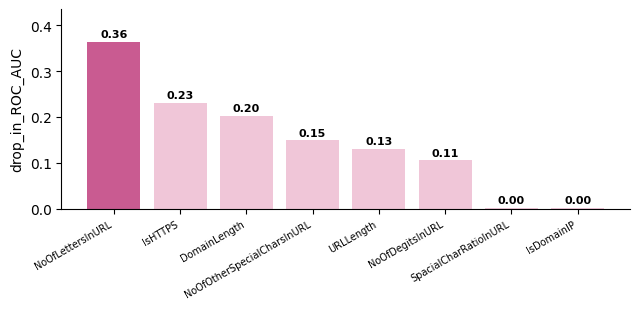

report\table_rq3_cost.csv (10, 5)


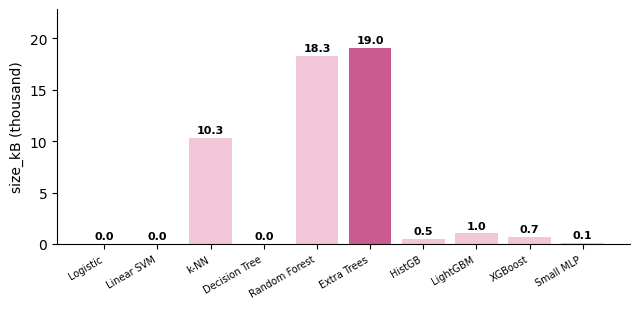

report\table_rq3_feature_ladder.csv (60, 6)
report\table_rq3_one_line_rule.csv (6, 2)


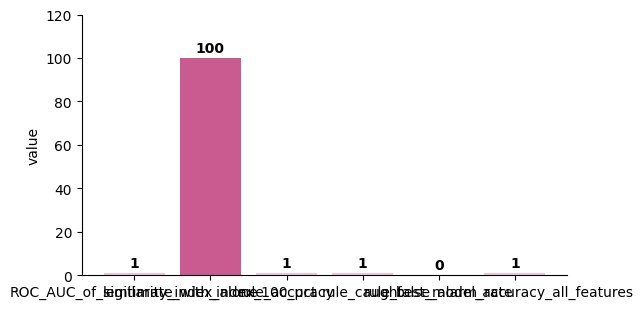

report\table_rq3_size_matched_control.csv (20, 12)


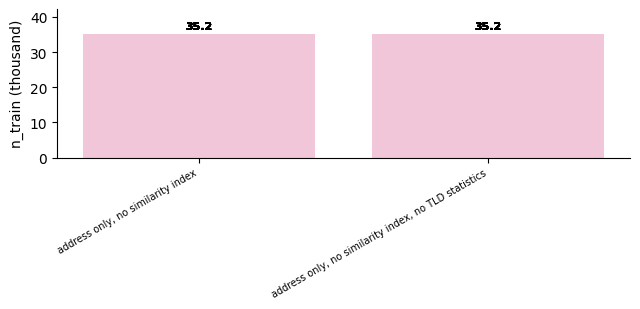

report\table_rq3_svm_score_quantiles.csv (3, 3)
report\table_rq3_threshold_diagnostic.csv (10, 4)


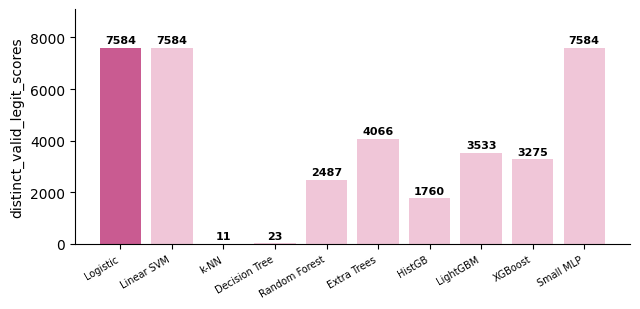

report\table_rq3_unseen_tld.csv (20, 8)


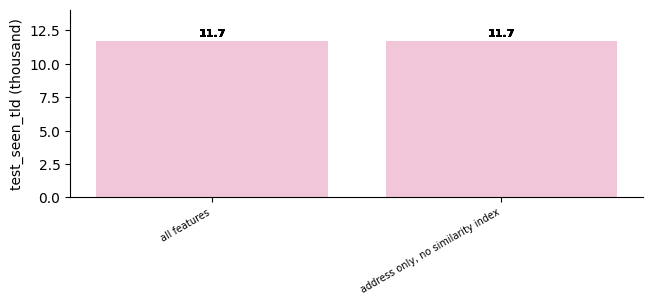

In [22]:
import glob
for f in sorted(glob.glob('report/table_rq3_*.csv')):
    t = pd.read_csv(f); numc = [c for c in t.columns[1:] if pd.api.types.is_numeric_dtype(t[c])]
    print(f, t.shape)
    if 2 <= len(t) <= 20 and numc and t[numc[0]].notna().all() and t[numc[0]].min() >= 0 and t[numc[0]].max() > 0:
        v, lab, fm = nice(t[numc[0]], numc[0]); bar_chart(t.iloc[:, 0].astype(str), v, lab, f.replace('table_', 'fig_').replace('.csv', '.png'), highlight=int(v.argmax()), fmt=fm)

## Test case và chẩn đoán

- **Làm gì:** kiểm tra tự động các sản phẩm của notebook.
- **Kiểm tra:** mọi `assert` qua. Sinh viên A chạy lại notebook này và ghi vào ô Đối chứng.

In [23]:
assert os.path.exists('report/table_rq2.csv') and os.path.exists('report/params_best.json')
assert len(glob.glob('report/table_rq3_*.csv')) >= 2, 'RQ3 tables missing'
assert os.path.exists('report/table_rq3_size_matched_control.csv')
assert res.iloc[:, 1].notna().all()
print(sorted(os.path.basename(f) for f in glob.glob('report/*')))
print('Notebook B: all checks passed')

['fig_eda_by_group.png', 'fig_eda_correlation.png', 'fig_eda_distributions.png', 'fig_eda_heatmap.png', 'fig_eda_target.png', 'fig_q1.png', 'fig_q2.png', 'fig_q3.png', 'fig_q4.png', 'fig_q7.png', 'fig_rq1.png', 'fig_rq2_models.png', 'fig_rq3_address_features.png', 'fig_rq3_cost.png', 'fig_rq3_one_line_rule.png', 'fig_rq3_size_matched_control.png', 'fig_rq3_threshold_diagnostic.png', 'fig_rq3_unseen_tld.png', 'paper_fig1_workflow.png', 'paper_fig2_url_form.png', 'paper_fig3_tld.png', 'paper_fig4_cost.png', 'paper_fig5_permutation.png', 'params_best.json', 'table_cleaning_log.csv', 'table_data_dictionary.csv', 'table_eda_by_group.csv', 'table_eda_correlation.csv', 'table_feasibility_gate.csv', 'table_feature_strength.csv', 'table_numeric_summary.csv', 'table_outliers.csv', 'table_q1.csv', 'table_q2.csv', 'table_q3.csv', 'table_q4.csv', 'table_q5.csv', 'table_q6.csv', 'table_q7.csv', 'table_q8.csv', 'table_review_control_domain_disjoint.csv', 'table_review_cross_dataset.csv', 'table_revie

### Đối chứng

| Người chạy lại | Ngày | Metric chính khớp | Ghi chú |
|---|---|---|---|
| | | | |

### Chẩn đoán

Nếu mô hình tốt nhất không hơn mốc đơn giản hoặc kết quả RQ3 trái dự kiến, ghi nguyên nhân có bằng chứng (thiếu đặc trưng, dữ liệu ít, lệch giữa hai tập) vào `report/table_diagnosis.csv`.

### Báo cáo tiến độ (dán vào kênh nhóm trước buổi báo cáo)

1. Việc đã xong, kèm tên file và số dòng, bảng, hình:
2. Con số chính mới có:
3. Vướng mắc và điều đã thử:
4. Việc sẽ làm đến lần báo cáo sau, ai làm:
5. Prompt AI đáng chú ý và Human Delta:

### Hình cho bài báo (hình chi phí và hình permutation)

Vẽ hình chi phí và hình permutation đúng kích thước khi in, từ `report/table_rq3_cost.csv` và `report/table_rq3_address_features.csv`. Không tính lại số liệu; ảnh lưu thành `report/paper_fig4_cost.png` và `report/paper_fig5_permutation.png`. Bài báo in hình permutation (Hình 4); số liệu chi phí nằm ở Bảng 6.

c:\Users\ASUS\Downloads\.venv\Lib\site-packages\matplotlib\_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse = parser.parseString(pattern)
c:\Users\ASUS\Downloads\.venv\Lib\site-packages\matplotlib\_fontconfig_pattern.py:89: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  parser.resetCache()
c:\Users\ASUS\Downloads\.venv\Lib\site-packages\matplotlib\_mathtext.py:2010: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
  p.space          = oneOf(self._space_widths)("space")
c:\Users\ASUS\Downloads\.venv\Lib\site-packages\matplotlib\_mathtext.py:2012: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
  p.style_literal  = oneOf(
c:\Users\ASUS\Downloads\.venv\Lib\site-packages\matplotlib\_mathtext.py:2020: PyparsingDeprecationWarning: 'leaveWhitespace' deprecated - use 'leave_whitespace'
  )("sym").leaveWhitespace()
c:\Users\ASUS\Downloads\.venv\Lib\site-packages\matplotlib\_math

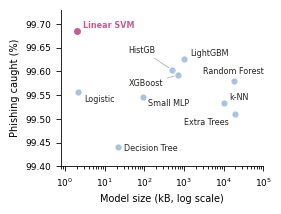

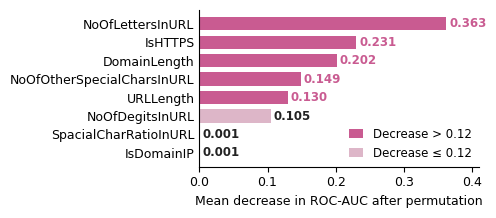

In [24]:
import matplotlib, matplotlib.pyplot as plt, numpy as np, pandas as pd
from matplotlib.patches import FancyBboxPatch
PINK, LPINK, BLUE, PURP, INK = '#C95B91', '#F0C6D8', '#A9C4E2', '#8E7CC3', '#222222'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 7, 'axes.linewidth': 0.6, 'xtick.major.width': 0.6, 'ytick.major.width': 0.6,
                     'xtick.labelsize': 6.5, 'ytick.labelsize': 6.5, 'axes.labelsize': 7, 'axes.titlesize': 7.5, 'legend.fontsize': 6.5})
TW = 15.1 / 2.54                                         # text width of the paper in inches, so that figures are drawn at printed size
def clean(ax): ax.spines[['top', 'right']].set_visible(False)

# Figure 4: phishing caught against model size (address features)
c = pd.read_csv('report/table_rq3_cost.csv')
fig, ax = plt.subplots(figsize=(0.45 * TW, 2.0))
for _, r in c.iterrows():
    sv = r.model == 'Linear SVM'
    ax.scatter(r.size_kB, 100 * r.caught_at_1pct_false_alarms, s=16 if sv else 12, color=PINK if sv else BLUE, zorder=3)
off = {'Logistic': (4, -7), 'Linear SVM': (4, 2), 'k-NN': (4, 2), 'Decision Tree': (4, -3), 'Extra Trees': (-4, -8), 'LightGBM': (4, 2), 'Small MLP': (4, -6)}
fixed = {'HistGB': (40, 99.645), 'XGBoost': (40, 99.575), 'Random Forest': (3e3, 99.60)}   # crowded models: label at a fixed place with a leader line, whatever the exact point
for _, r in c.iterrows():
    xy = (r.size_kB, 100 * r.caught_at_1pct_false_alarms)
    kw = dict(fontsize=5.8, color=PINK if r.model == 'Linear SVM' else INK, fontweight='bold' if r.model == 'Linear SVM' else 'normal')
    if r.model in fixed:
        ax.annotate(r.model, xy, xytext=fixed[r.model], textcoords='data', ha='left', va='center',
                    arrowprops=dict(arrowstyle='-', color='#9AA5B1', lw=0.5, shrinkA=1, shrinkB=2.5), **kw)
    else:
        dx, dy = off[r.model]
        ax.annotate(r.model, xy, xytext=(dx, dy), textcoords='offset points', ha='left' if dx > 0 else 'right', **kw)
ax.set_xscale('log'); ax.set_xlim(0.8, 1e5); ax.set_ylim(99.40, 99.73)
ax.set_xlabel('Model size (kB, log scale)'); ax.set_ylabel('Phishing caught (%)'); clean(ax)
fig.tight_layout(pad=0.3); fig.savefig('report/paper_fig4_cost.png', dpi=400); plt.show()

# Figure 5: permutation importance of the address-only Linear SVM
d = pd.read_csv('report/table_rq3_address_features.csv').iloc[::-1]
BASE = {k: v for k, v in matplotlib.rcParamsDefault.items() if k not in ('backend', 'backend_fallback', 'interactive')}
BASE.update({'font.size': 9, 'font.family': 'DejaVu Sans'})
with plt.rc_context(BASE):
    fig, ax = plt.subplots(figsize=(5.0, 2.25))
    col = [PINK if v > 0.12 else '#DDB6C8' for v in d.drop_in_ROC_AUC]
    ax.barh(d.feature, d.drop_in_ROC_AUC, color=col, height=0.72)
    for y, v, c_ in zip(range(len(d)), d.drop_in_ROC_AUC, col):
        ax.text(v + 0.004, y, '%.3f' % v, va='center', fontsize=8.5, fontweight='bold', color=PINK if c_ == PINK else INK)
    ax.set_xlabel('Mean decrease in ROC-AUC after permutation')
    ax.set_xlim(0, 0.41); ax.spines[['top', 'right']].set_visible(False); ax.tick_params(axis='y', length=0)
    from matplotlib.patches import Patch                                      # colour legend: dark = decrease above 0.12 (the rule used for `col`), light = at most 0.12
    ax.legend(handles=[Patch(facecolor=PINK, label='Decrease > 0.12'), Patch(facecolor='#DDB6C8', label='Decrease ≤ 0.12')], loc='lower right', frameon=False, fontsize=8.5, handlelength=1.2, borderaxespad=0.2)
    fig.tight_layout(); fig.savefig('report/paper_fig5_permutation.png', dpi=300); plt.show()